# Task 4.1 - CNN
Goal: Build a CNN to predict which class the image from the dataset belongs to, figuring out what each dinosaur should be fed.    
Deadline: 1st February

In [2]:
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt

import os
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

### Seeding for results reproducibility
Fixes randomness in: 
* weight initialization
* data shuffling
* train/val split

In [3]:
seed = 42

torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data Loading and Preprocessing

- Images are loaded from class-specific folders
- Converted to grayscale
- Resized to 64×64
- Normalized to [0,1]

In [ ]:
def load_images_from_folder(base_path, class_to_label, img_size=(64, 64)):
    X = []
    Y = []

    for class_name, label in class_to_label.items():
        class_folder = os.path.join(base_path, class_name)

        for file in os.listdir(class_folder):
            img_path = os.path.join(class_folder, file)

            # Read image (RGB)
            img = cv2.imread(img_path) 

            if img is None:
                continue  # skip corrupted files

            # Resize
            img = cv2.resize(img, img_size)

            X.append(img)
            Y.append(label)

    return np.array(X), np.array(Y)

In [194]:
class_to_label = {
    "Apatosaur Aphie's Apples": 0,
    "Bluplocephalus Bob's Blueberries": 1,
    "Cherizinoasaur Cher's Cherries": 2,
    "Corythosaurus Cory's Corn": 3,
    "Grapthorina Greta's Grapes": 4,
    "Pachycephalosaurus Perry's Peaches": 5,
    "Pepteranodon Pep's Peppers": 6,
    "Potoceratops Pott's Potatoes": 7,
    "Rhaspdodon Ribery's Raspberries": 8,
    "Stribecosaurus Stan's Strawberries": 9,
    "Thyreosaur Tim's Thyme": 10,
    "vacation_photos": 11
}

X_train, Y_train = load_images_from_folder("data/veggie_heap_training/", class_to_label)
X_test, Y_test = load_images_from_folder("data/veggie_heap_testing", class_to_label)

In [195]:
#Checking shape 
print("Train X shape:", X_train.shape)
print("Train Y shape:", Y_train.shape)
print("Test X shape:", X_test.shape)
print("Test Y shape:", Y_test.shape)
print("Unique labels:", np.unique(Y_train))

Train X shape: (9835, 64, 64, 3)
Train Y shape: (9835,)
Test X shape: (2424, 64, 64, 3)
Test Y shape: (2424,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]


In [196]:
#Normalizing pixel values to prevent exploding gradients
X_train = X_train / 255.0
X_test = X_test / 255.0

In [197]:
#Checking for class imbalance
class_names = list(class_to_label.keys())
unique, counts = np.unique(Y_train, return_counts=True)

for u, c in zip(unique, counts):
    print(f"{class_names[u]}: {c}")

Apatosaur Aphie's Apples: 1445
Bluplocephalus Bob's Blueberries: 1302
Cherizinoasaur Cher's Cherries: 654
Corythosaurus Cory's Corn: 945
Grapthorina Greta's Grapes: 423
Pachycephalosaurus Perry's Peaches: 360
Pepteranodon Pep's Peppers: 1478
Potoceratops Pott's Potatoes: 152
Rhaspdodon Ribery's Raspberries: 249
Stribecosaurus Stan's Strawberries: 306
Thyreosaur Tim's Thyme: 1591
vacation_photos: 930


## Dataset Preparation

- Data converted to PyTorch tensors
- Train-validation split applied (80-20)
- DataLoader used for batching and shuffling

* Tensors: Multi-dimensional array (like NumPy, but for deep learning)        
* Dataset: Wraps your data into a structured format   
* DataLoader: How data is given to model. It handles: 
    - batching
    - shuffling
    - iteration

In [198]:
# Convert to Pytorch Format

X_train_torch = torch.tensor(X_train, dtype=torch.float32).permute(0, 3, 1, 2)
X_test_torch = torch.tensor(X_test, dtype=torch.float32).permute(0, 3, 1, 2)

Y_train_torch = torch.tensor(Y_train, dtype=torch.long)
Y_test_torch = torch.tensor(Y_test, dtype=torch.long)

print("Train X shape:", X_train_torch.shape)
print("Train Y shape:", Y_train_torch.shape)
print("Test X shape:", X_test_torch.shape)
print("Test Y shape:", Y_test_torch.shape)

Train X shape: torch.Size([9835, 3, 64, 64])
Train Y shape: torch.Size([9835])
Test X shape: torch.Size([2424, 3, 64, 64])
Test Y shape: torch.Size([2424])


In [199]:
# Create DataLoader

train_dataset = TensorDataset(X_train_torch, Y_train_torch)
test_dataset = TensorDataset(X_test_torch, Y_test_torch)

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

## Model Architecture

The CNN consists of:
- 3 Convolutional layers for feature extraction
- MaxPooling layers for downsampling
- Fully connected layers for classification

In [ ]:
#CNN Model

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3)    # extracts features
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2,2)

        self.fc1 = nn.Linear(128 * 6 * 6, 64)       # classification
        self.fc2 = nn.Linear(64, 12)

    def forward(self, X):
        X = self.pool(F.relu(self.bn1(self.conv1(X))))
        X = self.pool(F.relu(self.bn2(self.conv2(X))))
        X = self.pool(F.relu(self.bn3(self.conv3(X))))

        X = X.view(X.size(0), -1)

        X = F.relu(self.fc1(X))
        X = self.fc2(X)

        return X

## Training Process

- Loss Function: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epochs: 10

In [201]:
# Training setup

model = CNN()

#criterion = nn.CrossEntropyLoss()
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
)

class_weights = torch.tensor(class_weights, dtype=torch.float32)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# Training Loop

epochs = 10
train_accs = []
val_accs = []

for epoch in range(epochs):

    # TRAINING
    model.train()   # sets model to training mode -> affects dropout(enabled), BatchNorm
    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()   # clears old gradients

        outputs = model(images) # Prediction/Forward prop
        loss = criterion(outputs, labels) # Loss computed

        loss.backward()     # Gradients computed
        optimizer.step()    # Gradients updated

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total

    # VALIDATION 
    model.eval()        # Sets model to evaluation mode -> dropout(disabled), BatchNorm uses previously stored mean and variance instead of computing a new one
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1, Train Acc: 0.8114, Val Acc: 0.9263
Epoch 2, Train Acc: 0.9310, Val Acc: 0.9181
Epoch 3, Train Acc: 0.9487, Val Acc: 0.9436
Epoch 4, Train Acc: 0.9652, Val Acc: 0.9548
Epoch 5, Train Acc: 0.9778, Val Acc: 0.9827
Epoch 6, Train Acc: 0.9854, Val Acc: 0.9232
Epoch 7, Train Acc: 0.9644, Val Acc: 0.9761
Epoch 8, Train Acc: 0.9911, Val Acc: 0.9461
Epoch 9, Train Acc: 0.9811, Val Acc: 0.9624
Epoch 10, Train Acc: 0.9816, Val Acc: 0.9863


## Model Evaluation

The model is evaluated using:
- Test Accuracy
- Confusion Matrix
- Sample Predictions

In [203]:
# Evaluation

all_preds = []
all_labels = []

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_preds.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

print("Test Accuracy:", correct / total)

Test Accuracy: 0.7322607260726073


In [204]:
print(classification_report(all_labels, all_preds, target_names=class_names))

f1 = f1_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
precision = precision_score(all_labels, all_preds, average='macro')

print("F1 (macro):", f1)
print("Recall (macro):", recall)
print("Precision (macro):", precision)

                                    precision    recall  f1-score   support

          Apatosaur Aphie's Apples       0.47      0.96      0.64       200
  Bluplocephalus Bob's Blueberries       0.66      1.00      0.80       200
    Cherizinoasaur Cher's Cherries       1.00      0.99      1.00       200
         Corythosaurus Cory's Corn       0.98      1.00      0.99       217
        Grapthorina Greta's Grapes       0.90      0.60      0.72       150
Pachycephalosaurus Perry's Peaches       0.54      0.37      0.44       199
        Pepteranodon Pep's Peppers       0.86      0.56      0.68       200
      Potoceratops Pott's Potatoes       0.60      0.35      0.44       200
   Rhaspdodon Ribery's Raspberries       0.69      0.98      0.81       122
Stribecosaurus Stan's Strawberries       0.95      0.99      0.97       150
            Thyreosaur Tim's Thyme       0.72      0.39      0.51       373
                   vacation_photos       0.74      0.96      0.84       213

          

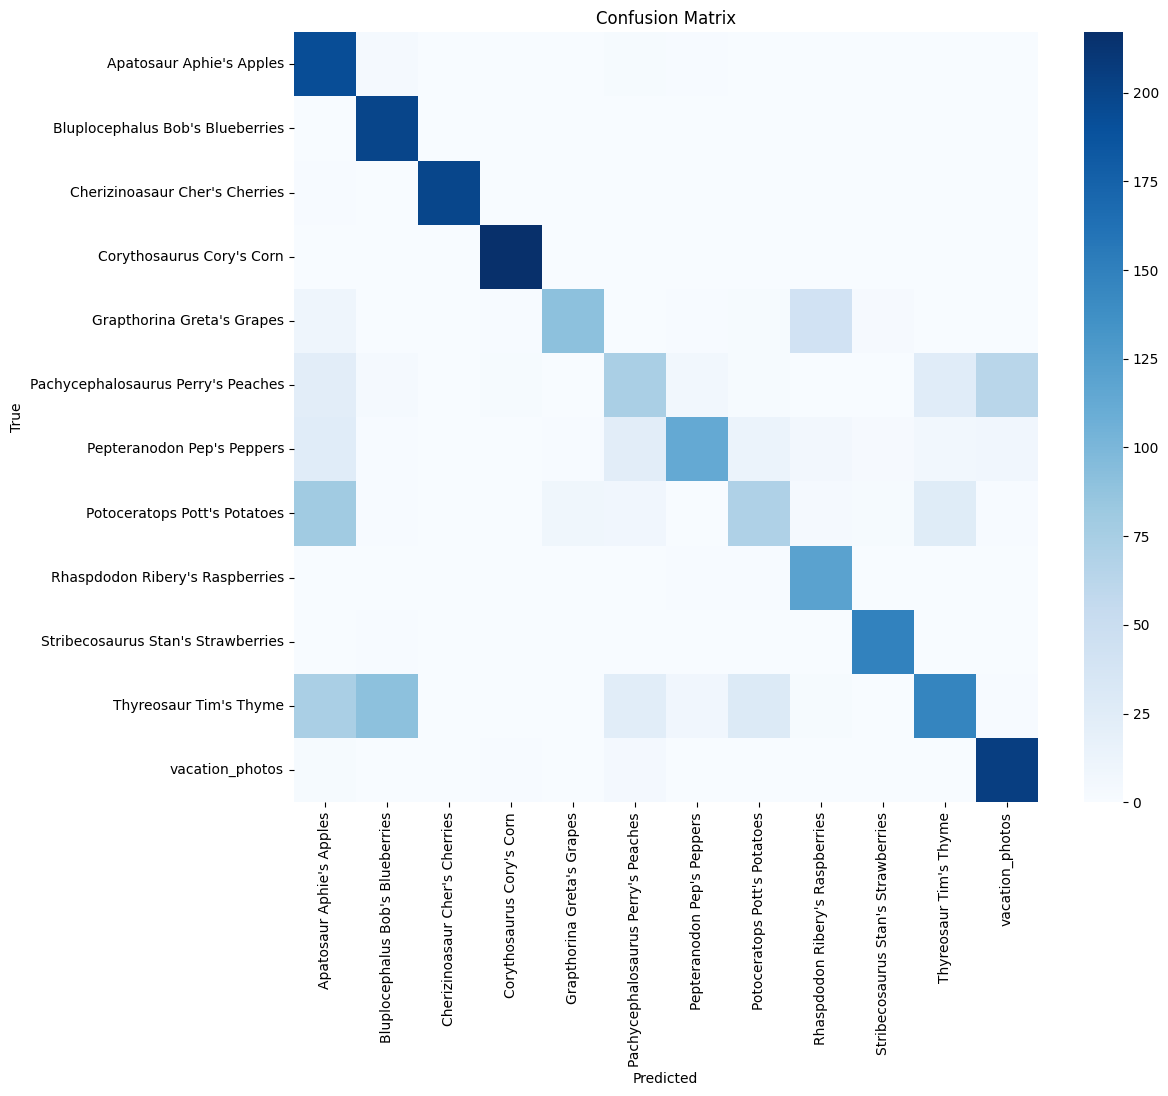

In [205]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=False, cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

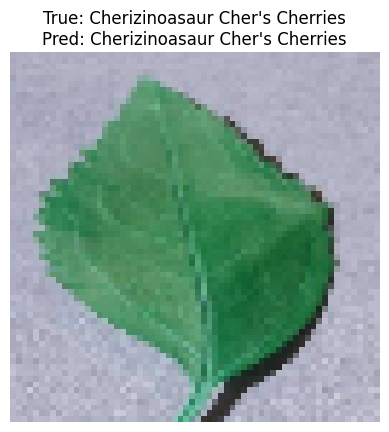

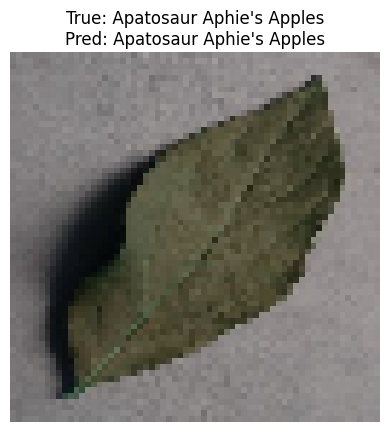

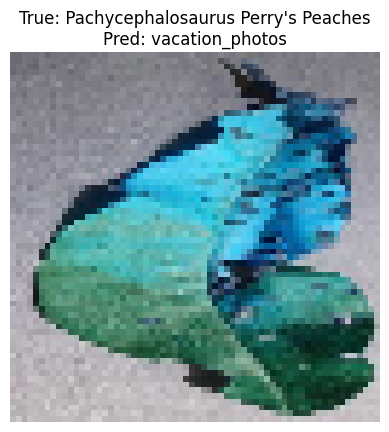

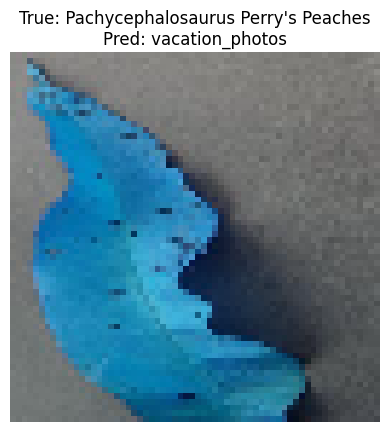

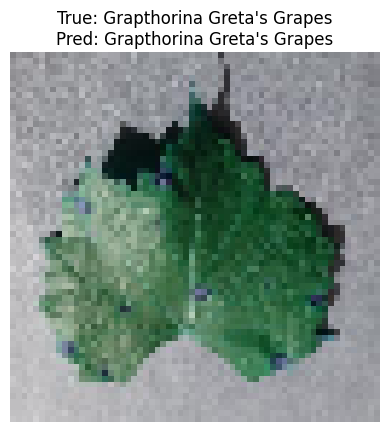

In [206]:
# Prediction Visualization

for _ in range(5):
    idx = random.randint(0, len(X_test_torch)-1)
    
    image = X_test_torch[idx]
    label = Y_test[idx]

    with torch.no_grad():
        output = model(image.unsqueeze(0))
        _, pred = torch.max(output, 1)

    plt.imshow(image.permute(1, 2, 0))
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred.item()]}")
    plt.axis('off')
    plt.show()

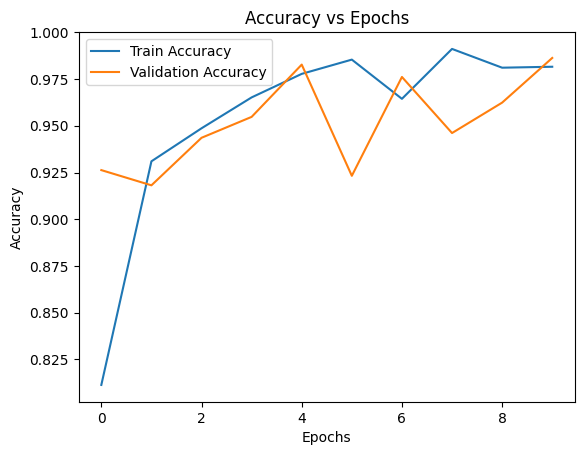

In [207]:
# Training Graphs

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

## Final Results and Conclusion

### Model Performance
The Convolutional Neural Network (CNN) was trained to classify 64×64 RGB images into 12 categories (11 food classes + 1 vacation class). 

- Final Training Accuracy: ~97–98%
- Final Validation Accuracy: ~93–96%
- Test Accuracy: **73-77%**
- Macro F1 Score: ~0.73

The model demonstrates strong learning capability, with high training and validation accuracy. The improved test performance compared to earlier experiments indicates better generalization after architectural and input improvements.

---

### Impact of RGB vs Grayscale

Switching from grayscale to RGB significantly improved performance:

- Better separation of visually similar classes
- Improved macro F1 score (~0.60 → ~0.71)
- Higher test accuracy (~63% → ~74%)

This confirms that color information plays a crucial role in distinguishing between similar food categories.

--- 

### Effect of Adding Vacation Class
A 12th class ("vacation_photos") was introduced to handle out-of-distribution images.

This resulted in:

- Improved robustness to unrelated inputs
- High recall for vacation images (~0.94)
- Minimal interference with food classification

The model successfully learned to distinguish relevant vs irrelevant inputs, which is an important real-world capability.

---

### Observations from Confusion Matrix
- Excellent performance on distinct classes:
  - Corn, cherries, blueberries, strawberries
- Major confusion occurs between:
  - Grapes vs apples/peaches
  - Potatoes vs peppers
  - Peaches (low recall)

This indicates:
- Some classes lack strong distinguishing features
- Dataset imbalance and visual similarity affect performance

---

### Limitations
- Class imbalance (e.g., potatoes, peaches underrepresented)
- Some classes have high visual similarity
- Slight overfitting (train >> test gap)

---

### Key Improvements Applied

- Switched to RGB input
- Added Batch Normalization
- Reduced fully connected layer size (better generalization) 
- Introduced validation split
- Evaluated using precision, recall, and F1-score

---

### Possible Future Improvements

- Data augmentation (rotation, flipping, brightness variation)
- Class weighting to handle imbalance
- Learning rate scheduling
- Deeper CNN or transfer learning (e.g., ResNet)

---

### Final Conclusion
The CNN successfully learns meaningful visual patterns and achieves ~74% test accuracy with strong macro F1 performance. The addition of RGB channels and a "vacation" class significantly improved robustness and generalization.

While challenges remain in distinguishing visually similar and underrepresented classes, the model demonstrates a solid and practical image classification pipeline.

### Personal Notes
* (N,C,H,W)->expected shape for input in pytorch (C=channel)
* No need for one hot encoding since pytorch expects integer labels since we are using nn.CrossEntopyLoss() which already:
    1. Applies Softmax
    2. Computes Cross-Entropy Loss 
* So, model output will also be raw logits[NO Softmax], since nn.CrossEntopyLoss() handles that 
* Dataloader(Pytorch Concept): Used for processing data samples. Handles:
    1. Batching (Dividing samples into batches) 
    2. Shuffling (Prevents learning order-based patters) 
    3. Results in efficient memory usage + Doesn't overload RAM/GPU + cleaner training loop
* Adding a 12th class improved model robustness
* Struggles with similar classes (apple <-> peaches) -> identified using confusion matrix
* RGB > Grayscale for this dataset
* BatchNorm improved stability
* Reducing FC layer size improved generalization
* Severe class imbalance in dataset